In [1]:
from PIL import Image
from load_model import load_model, preprocess

model = load_model('Cardiomegaly')  # also 'Edema' or 'Atelectasis'
image = Image.open('images/02_positive_negative/02_01_original.jpg').convert('RGB')
x = preprocess(image)
logit = model(x)                    # shape [1, 1]: positive-finding logit
score = logit.sigmoid().item()      # score in [0, 1]; not calibrated confidence

In [13]:
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

MODELS = ['Cardiomegaly', 'Edema', 'Atelectasis']
models = {name: load_model(name) for name in MODELS}
labels = pd.read_csv('images.csv').set_index('image_id')


def grad_cam(model, x, layer='features.norm5'):
    """Grad-CAM for the positive logit model(x)[0, 0].

    layer: name of the target layer, e.g. 'features.norm5' (default, last conv-block
    output, 8x8 for a 256x256 input), 'features.denseblock3' (16x16), ...
    No no_grad()/inference_mode(): we need gradients; model stays in eval mode.
    """
    store = {}

    def fwd_hook(module, inp, out):
        store['act'] = out
        out.register_hook(lambda g: store.__setitem__('grad', g))

    handle = model.get_submodule(layer).register_forward_hook(fwd_hook)
    model.zero_grad()
    logit = model(x)[0, 0]
    logit.backward()
    handle.remove()

    act, grad = store['act'].detach(), store['grad'].detach()
    weights = grad.mean(dim=(2, 3), keepdim=True)            # one weight per channel
    cam = F.relu((weights * act).sum(dim=1, keepdim=True))   # [1, 1, h, w]
    cam = F.interpolate(cam, size=x.shape[-2:], mode='bilinear', align_corners=False)[0, 0]
    cam = cam / (cam.max() + 1e-8)                           # per-map normalisation to [0, 1]
    return cam.numpy(), logit.item()


def show_cam(ax, image, cam, title=''):
    """Overlay a Grad-CAM map on the 256x256 RGB image."""
    ax.imshow(image.convert('RGB').resize((256, 256), Image.Resampling.BILINEAR))
    ax.imshow(cam, cmap='jet', alpha=0.4, vmin=0, vmax=1)
    ax.set_title(title, fontsize=9)
    ax.axis('off')


def plot_gradcam_grid(image_ids, model_names=MODELS, layer='features.norm5', save_as=None):
    """One row per image: original + one Grad-CAM overlay per model, for the given layer."""
    fig, axes = plt.subplots(len(image_ids), len(model_names) + 1,
                             figsize=(3 * (len(model_names) + 1), 3.2 * len(image_ids)),
                             squeeze=False)
    for i, image_id in enumerate(image_ids):
        meta = labels.loc[image_id]
        image = Image.open(meta.image_path).convert('RGB')
        x = preprocess(image)
        axes[i, 0].imshow(image.resize((256, 256), Image.Resampling.BILINEAR))
        axes[i, 0].set_title(f'{image_id}\n{meta.sex}, {meta.age}y, {meta.view}', fontsize=9)
        axes[i, 0].axis('off')
        for j, name in enumerate(model_names):
            cam, logit = grad_cam(models[name], x, layer)
            score = torch.sigmoid(torch.tensor(logit)).item()
            show_cam(axes[i, j + 1], image, cam,
                     f'{name}\nlogit {logit:.2f} | score {score:.2f} | label {meta[name]}')

    fig.suptitle(f'Grad-CAM ({layer}) for the positive logit', fontsize=11)
    plt.tight_layout()
    if save_as:
        plt.savefig(f'/Users/ritasantos/Documents/DTU/Fall2026/02517/Responsible_AI/notebooks/project3/week3/results/{save_as}', dpi=200, bbox_inches='tight')
    plt.show()

## 1. When does a model look
Run all three models on each image. Compare prediction/logits and Grad-CAM. Hint: do highlighted regions differ with the predicted pathology? Which regions appear consistent with it?
### Images to use
01_compare_models: all three images

In [3]:
for model_name in ['Cardiomegaly', 'Edema', 'Atelectasis']:
    model = load_model(model_name)
    print(model_name)
    
    for image_path in ['images/01_compare_models/01_01_original.jpg',
                       'images/01_compare_models/01_02_original.jpg',
                       'images/01_compare_models/01_03_original.jpg']:
        image = Image.open(image_path).convert('RGB')
        x = preprocess(image)
        logit = model(x)
        score = logit.sigmoid().item()
        print(f'{image_path.split(sep="/")[-1]}: Score: {score:.3f}')
    

Cardiomegaly
01_01_original.jpg: Score: 0.695
01_02_original.jpg: Score: 0.580
01_03_original.jpg: Score: 0.620
Edema
01_01_original.jpg: Score: 0.756
01_02_original.jpg: Score: 0.691
01_03_original.jpg: Score: 0.650
Atelectasis
01_01_original.jpg: Score: 0.611
01_02_original.jpg: Score: 0.667
01_03_original.jpg: Score: 0.558


In [4]:
test1_ids = ['01_01_original', '01_02_original', '01_03_original']

rows, cams = [], {}
for image_id in test1_ids:
    image = Image.open(labels.loc[image_id, 'image_path']).convert('RGB')
    x = preprocess(image)
    for name in MODELS:
        cam, logit = grad_cam(models[name], x)
        cams[(image_id, name)] = cam
        rows.append({'image': image_id, 'model': name, 'logit': logit,
                     'score': torch.sigmoid(torch.tensor(logit)).item(),
                     'label': labels.loc[image_id, name]})  # 1 pos, -1 uncertain, NaN unmentioned

results1 = pd.DataFrame(rows)
results1.pivot(index='image', columns='model', values=['logit', 'score', 'label']).round(3)

logit                           score               \
model          Atelectasis Cardiomegaly  Edema Atelectasis Cardiomegaly   
image                                                                     
01_01_original       0.451        0.824  1.131       0.611        0.695   
01_02_original       0.695        0.324  0.806       0.667        0.580   
01_03_original       0.233        0.488  0.618       0.558        0.620   

                            label                     
model           Edema Atelectasis Cardiomegaly Edema  
image                                                 
01_01_original  0.756         1.0          1.0  -1.0  
01_02_original  0.691         1.0          1.0   1.0  
01_03_original  0.650         1.0          1.0   1.0

Os modelos que estamos a usar são binários e respondem a "esta imagem tem a patologia 'Cardiomegaly'/'Edema'/'Atelectasis'? Portanto, a ultima camada devolve apenas um valor:

- Logit: número bruto, resultado direto da camada linear e pode ir de menos a mais infinito.
    - logit > 0: o modelo inclina-se para "positivo"
    - logit < 0: inclina-se para "negativo"
    - logit = 0: está indeciso
    - quanto maior o valor em módulo, mais "convicto" está o modelo

- Score: Logit passado por uma sigmoide que o mete entre 0 e 1.
    - Não é uma probabilidade real (""not calibrated confidence". Um score de 0.69 não quer dizer que há 69% de probabilidade de cardiomegalia") - usamos apenas a comparação;

### Grad-CAM along model architecture layers

-- Model architecture: --
conv0 -> Conv2d


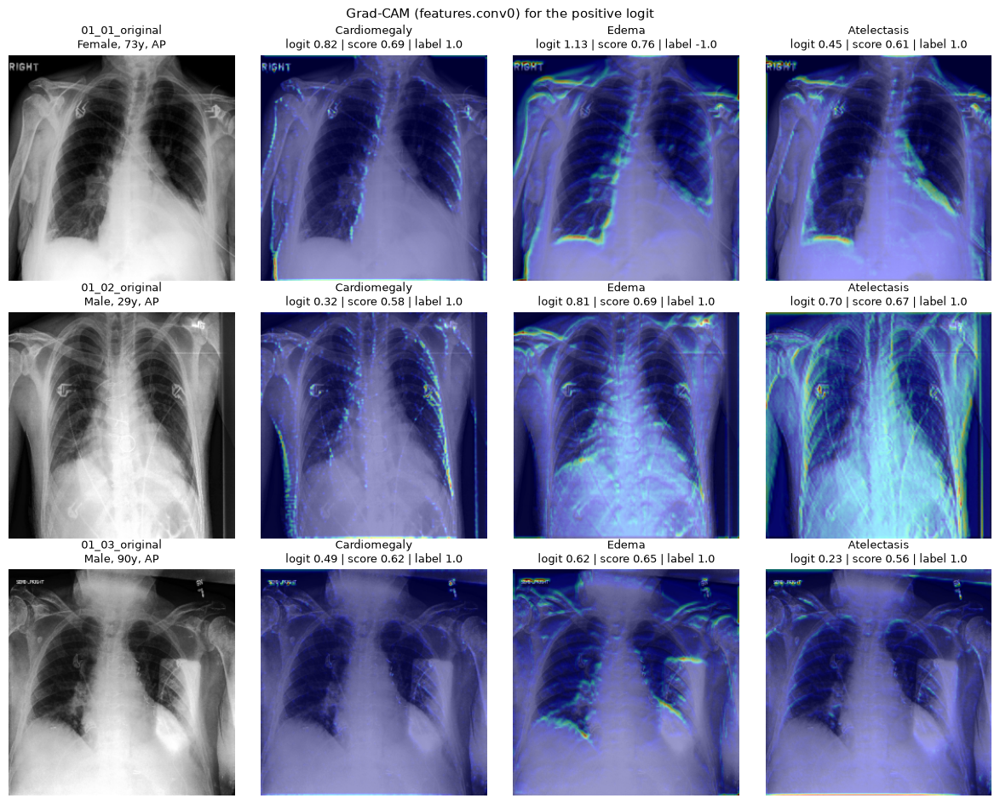

norm0 -> BatchNorm2d


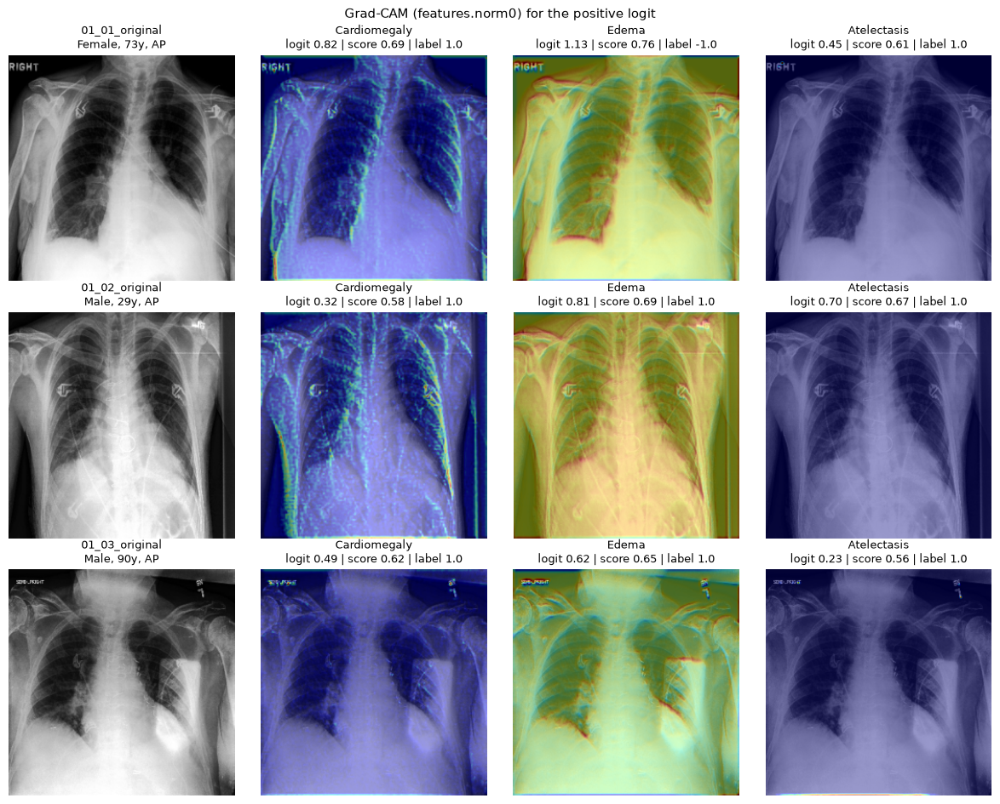

relu0 -> ReLU


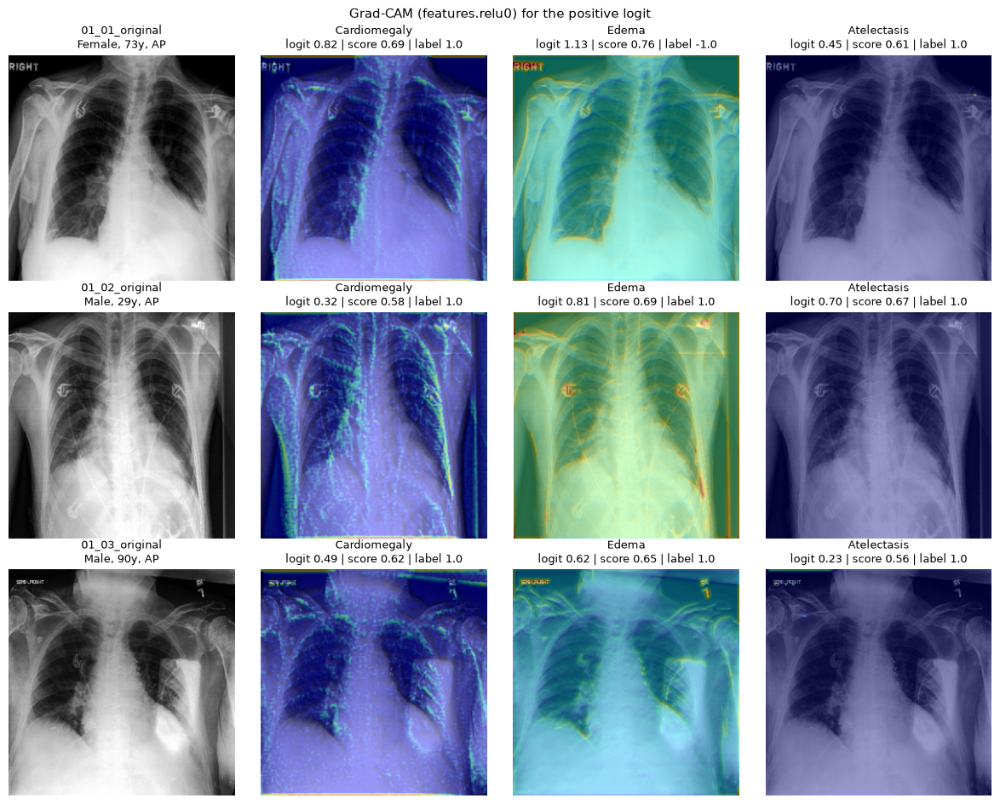

pool0 -> MaxPool2d


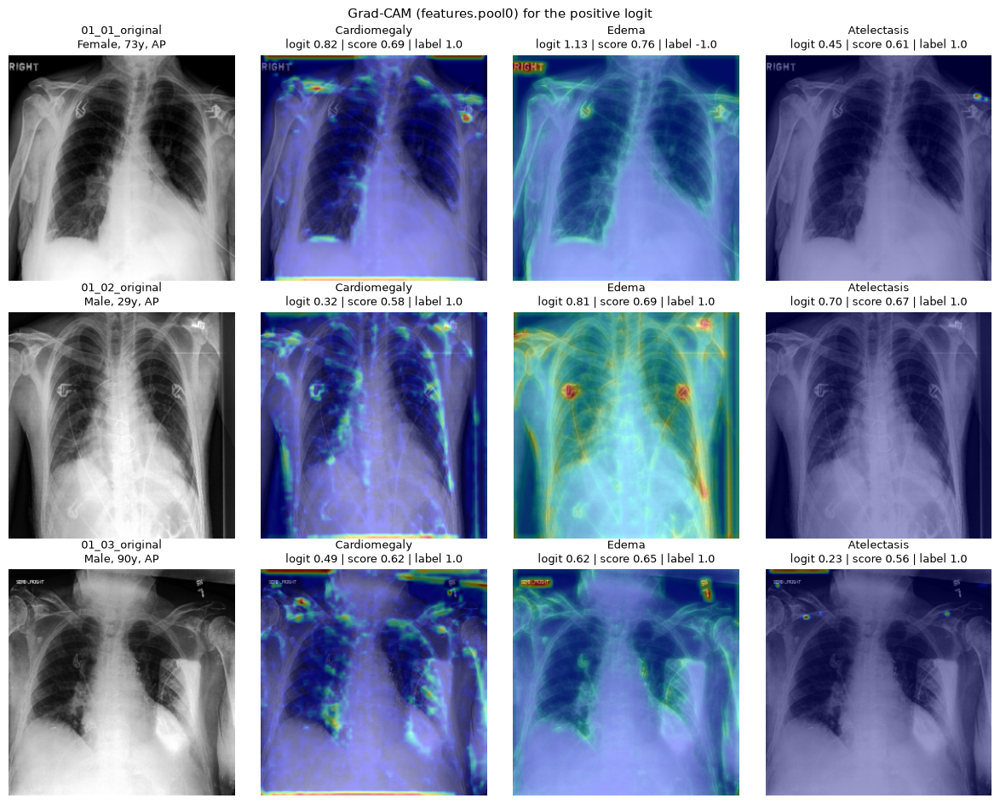

denseblock1 -> _DenseBlock


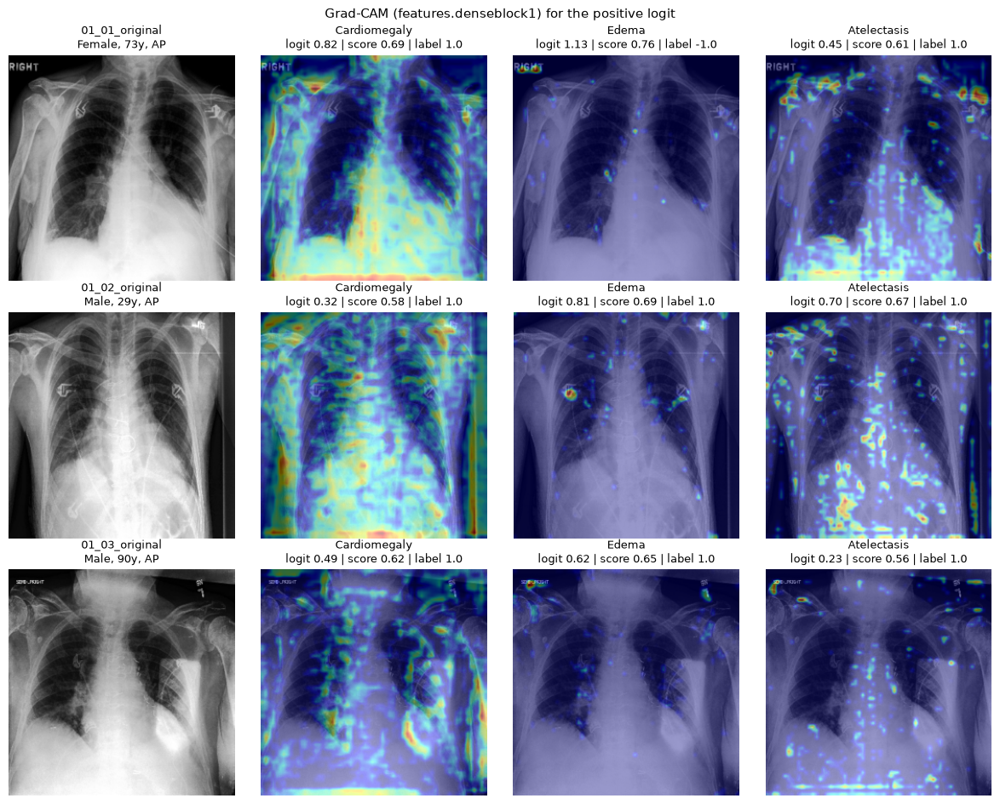

transition1 -> _Transition


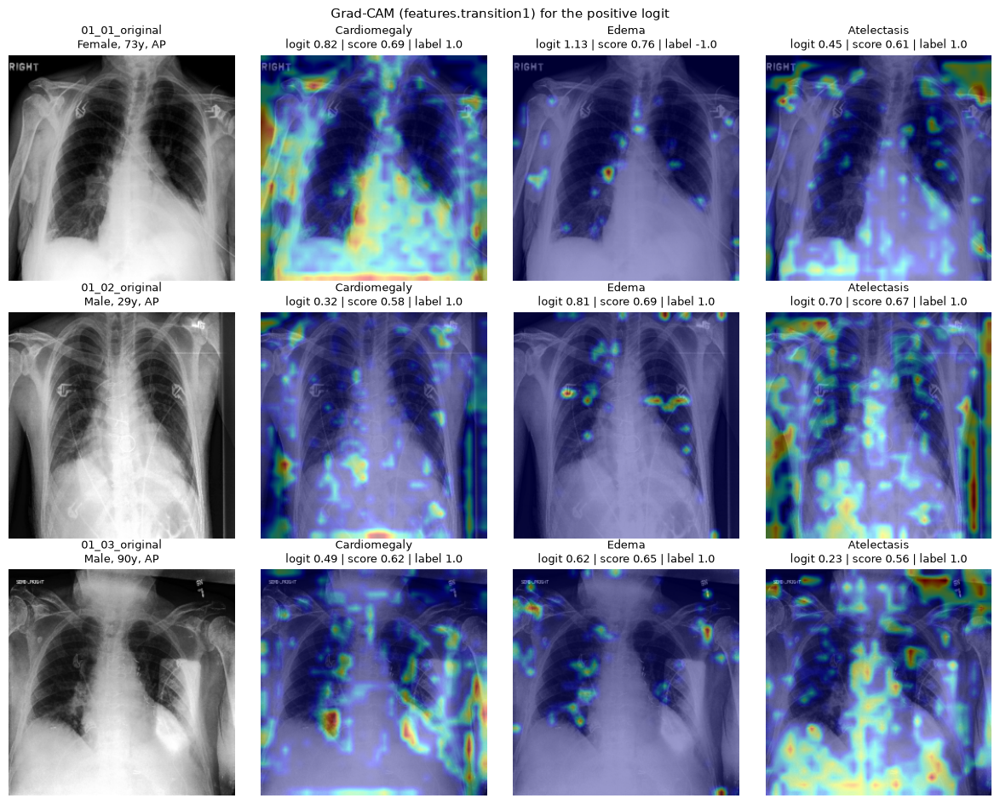

denseblock2 -> _DenseBlock


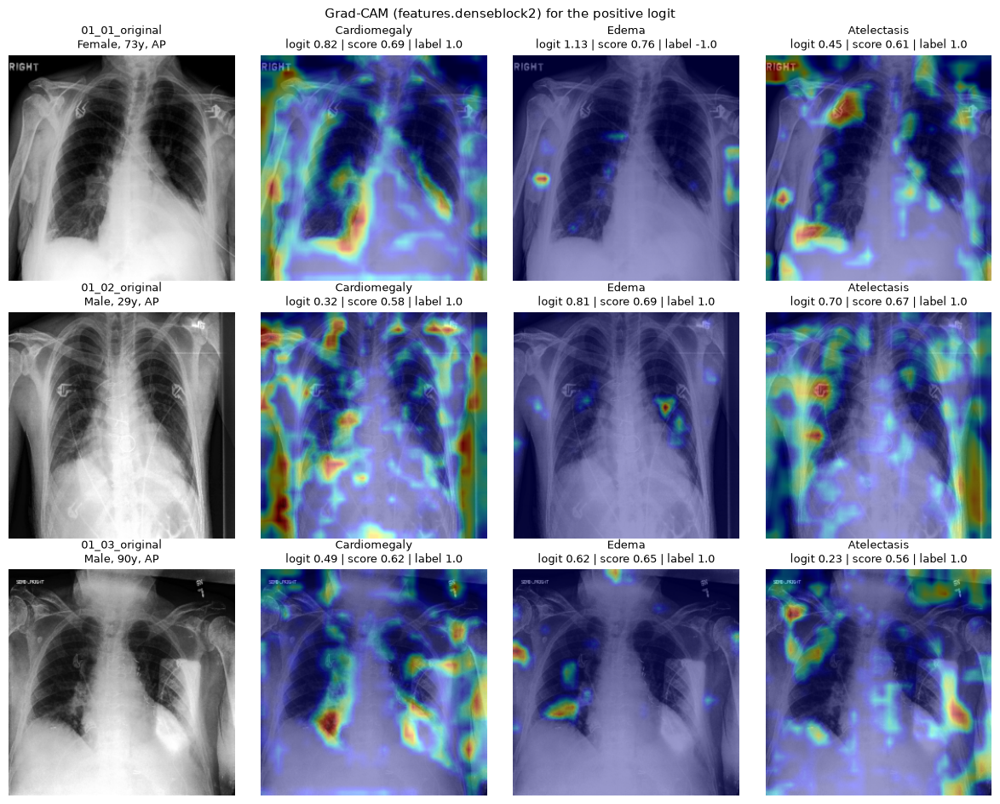

transition2 -> _Transition


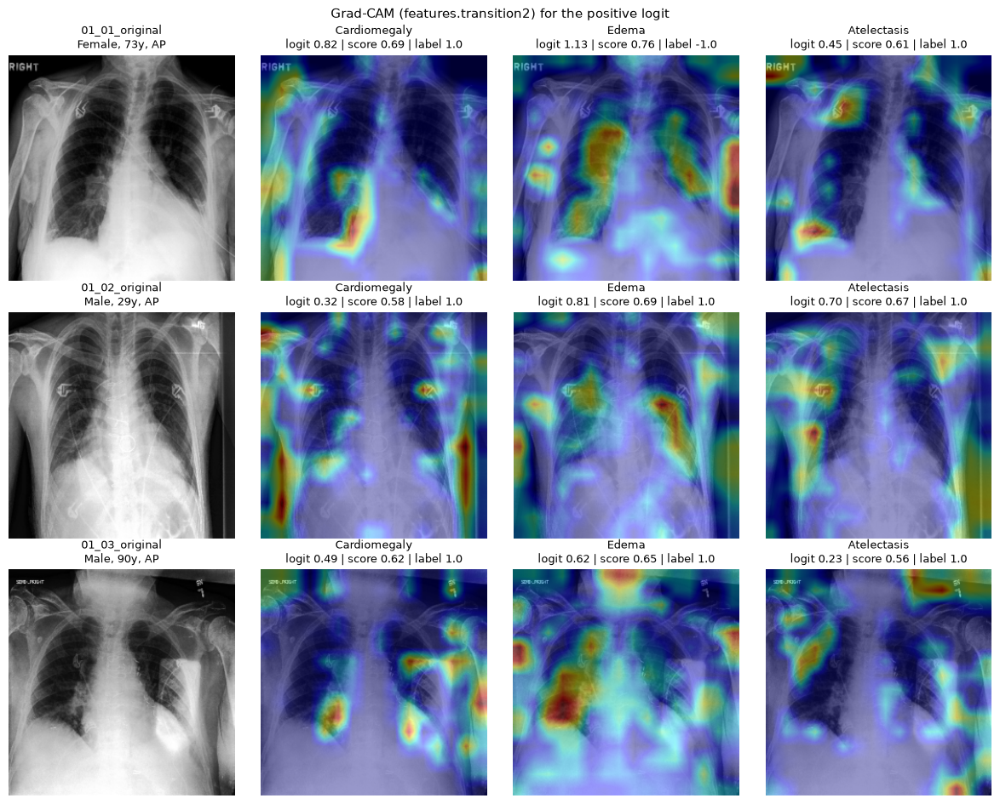

denseblock3 -> _DenseBlock


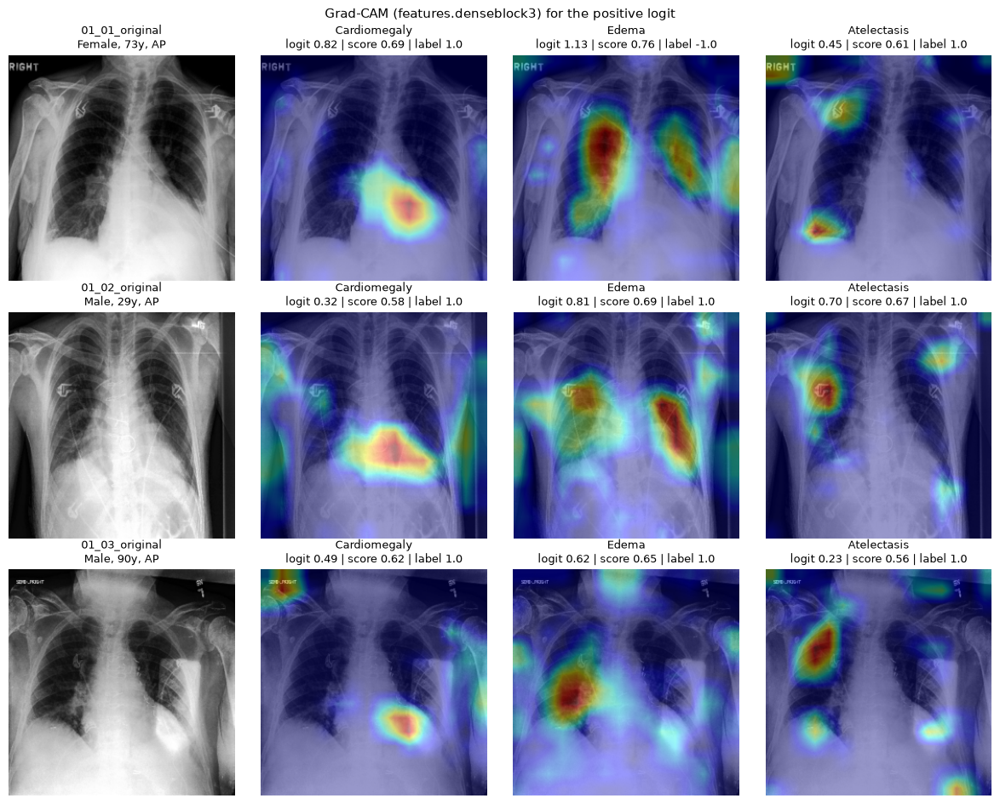

transition3 -> _Transition


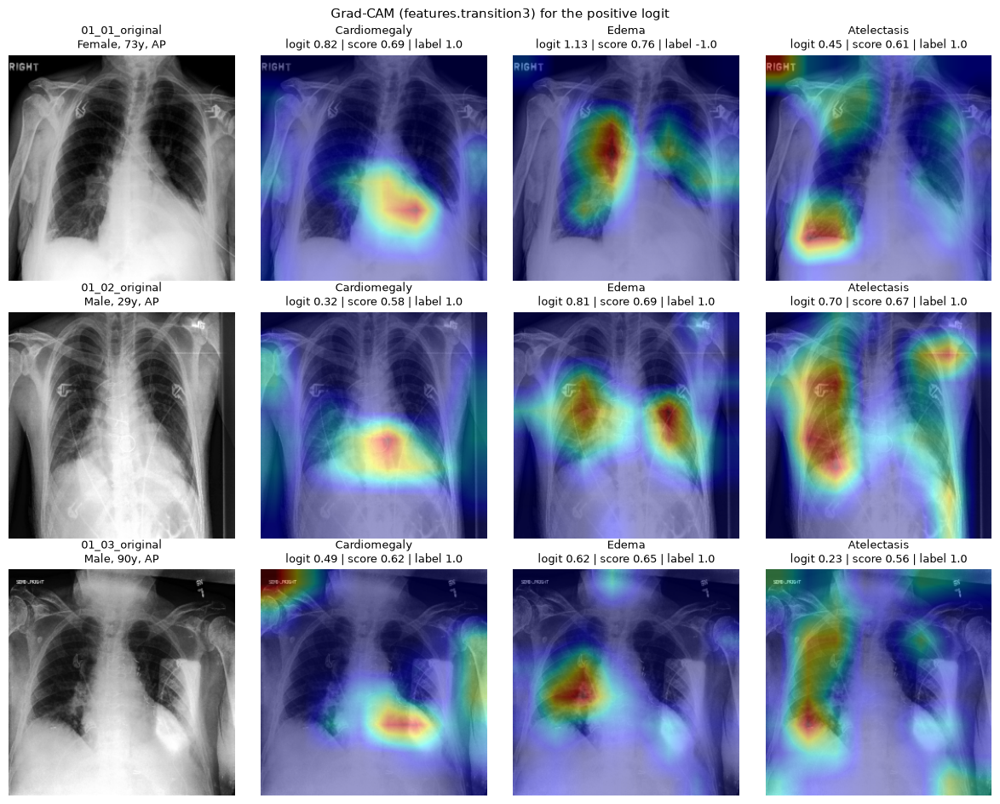

denseblock4 -> _DenseBlock


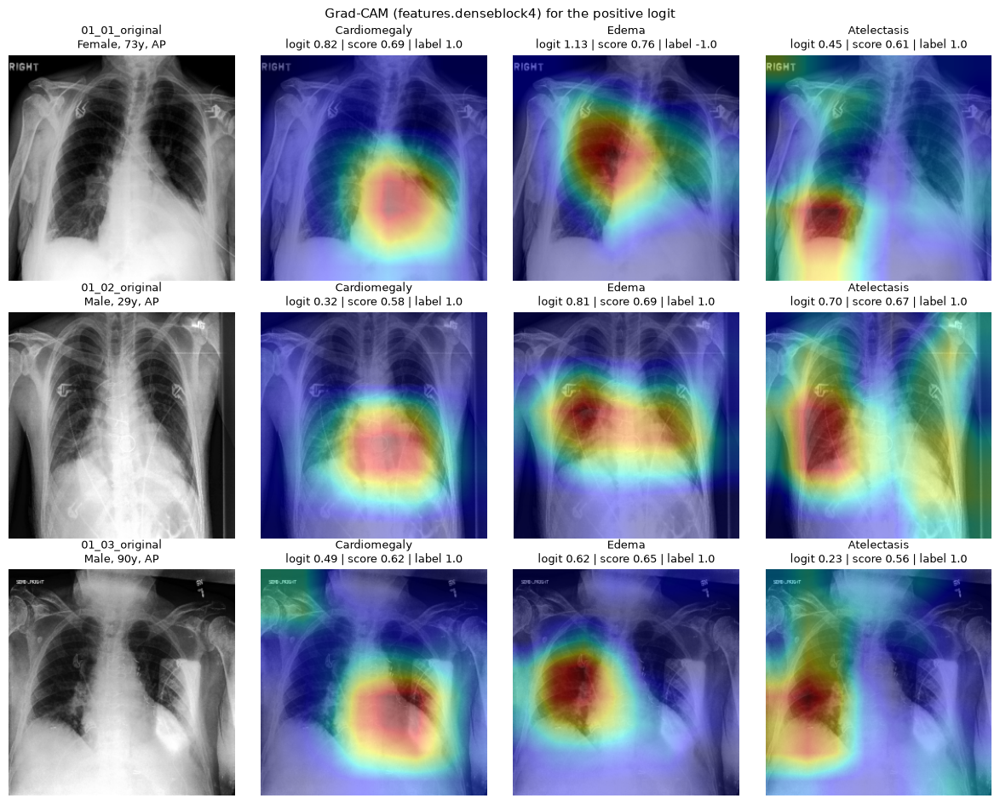

norm5 -> BatchNorm2d


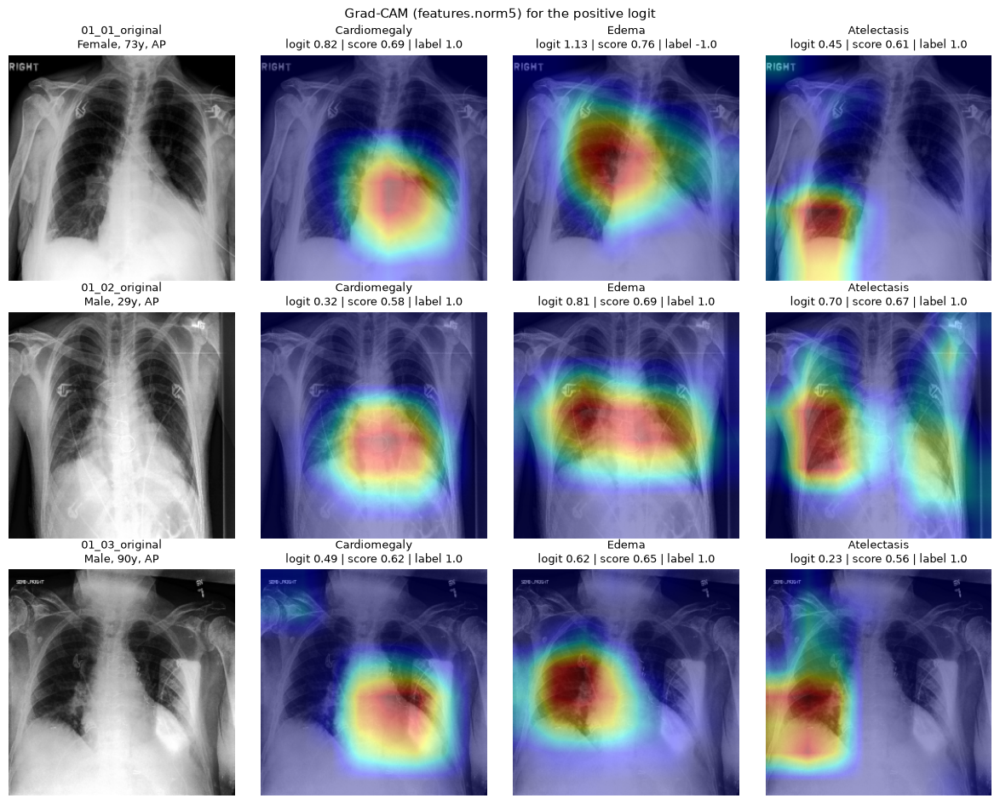

In [23]:
print('-- Model architecture: --')
for name, layer in model.features.named_children():
    print(name, '->', type(layer).__name__)
    plot_gradcam_grid(test1_ids, layer=f'features.{name}', save_as=f'test1_gradcam_{name}.png')


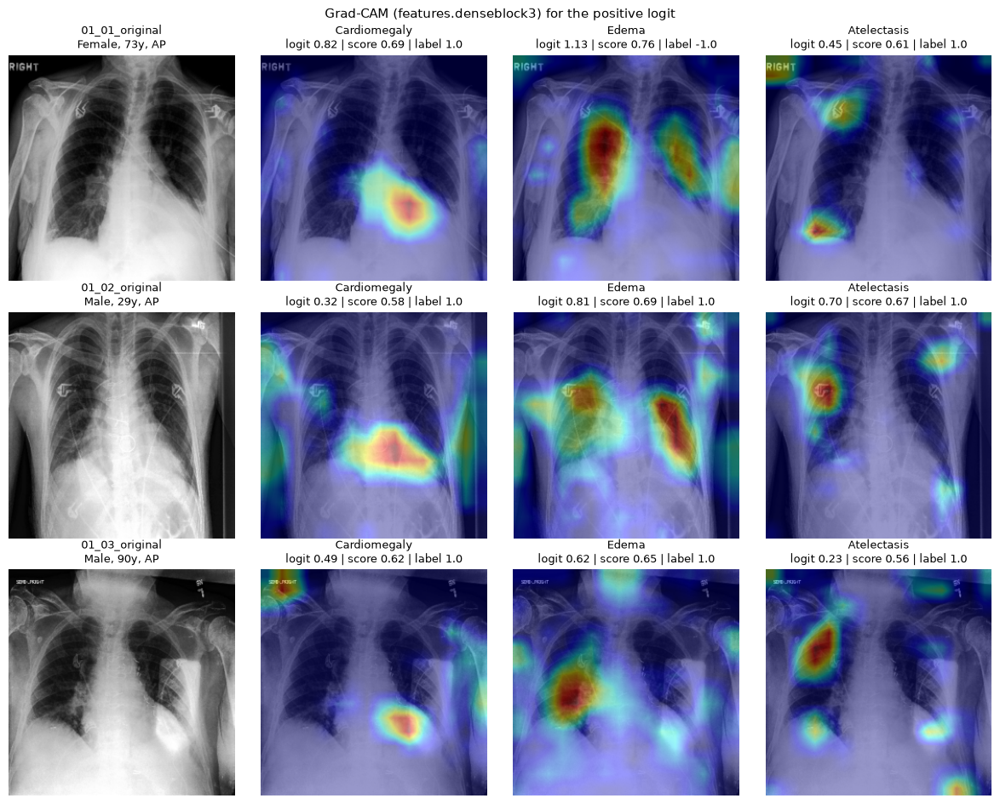

In [22]:
plot_gradcam_grid(test1_ids, layer='features.denseblock3', save_as='test1_gradcam_denseblock3.png')

## 2. Positive vs negative